In [ ]:
## Practica 4: Programaciòn lineal.

In [1]:
#Importación de librerías
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog

#ajustar tamaño de las gráficas
plt.rcParams["figure.figsize"] = (8, 5)

In [2]:
#Definición de datos del modelo 
coef_utilidad = np.array([40.0, 70.0])

# Restricciones de desigualdad
matriz_restricciones = np.array([
    [2.0, 4.0],   # Restricción 1: 2*x1 + 4*x2 ≤ 120 (Energía / Racks)
    [3.0, 2.0],   # Restricción 2: 3*x1 + 2*x2 ≤ 105 (Red / Almacenamiento)
    [0.0, -1.0]   # Restricción 3: -x2 ≤ -10 → x2 ≥ 10 (Mínimo servicio GPU)
])
vector_limites = np.array([120.0, 105.0, -10.0])
# Límites de no negatividad de las variables
limites_variables = [(0, None), (0, None)]
# Imprimir datos del modelo
print("Datos del modelo:")
print(f"Coeficientes: {coef_utilidad}")
print("\nMatriz de restricciones:")
print(matriz_restricciones)
print(f"\nValores límite: {vector_limites}")

Datos del modelo:
Coeficientes: [40. 70.]

Matriz de restricciones:
[[ 2.  4.]
 [ 3.  2.]
 [ 0. -1.]]

Valores límite: [120. 105. -10.]


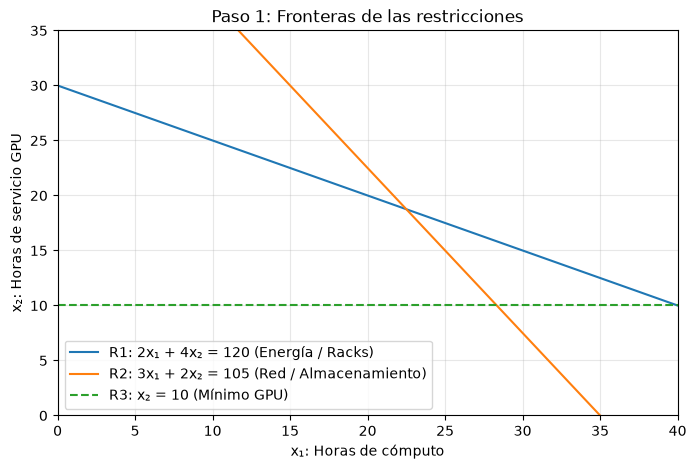

In [3]:
#Paso 1: Graficar fronteras de restricciones 
valores_x1 = np.linspace(0, 45, 400)

# Despejar x2 para cada restricción
frontera_r1 = (120 - 2 * valores_x1) / 4
frontera_r2 = (105 - 3 * valores_x1) / 2
frontera_r3 = np.full_like(valores_x1, 10.0)

# Crear gráfica
fig, ax = plt.subplots()
ax.plot(valores_x1, frontera_r1, label="R1: 2x₁ + 4x₂ = 120 (Energía / Racks)")
ax.plot(valores_x1, frontera_r2, label="R2: 3x₁ + 2x₂ = 105 (Red / Almacenamiento)")
ax.plot(valores_x1, frontera_r3, linestyle="--", label="R3: x₂ = 10 (Mínimo GPU)")

ax.set_xlim(0, 40)
ax.set_ylim(0, 35)
ax.set_xlabel("x₁: Horas de cómputo")
ax.set_ylabel("x₂: Horas de servicio GPU")
ax.set_title("Paso 1: Fronteras de las restricciones")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

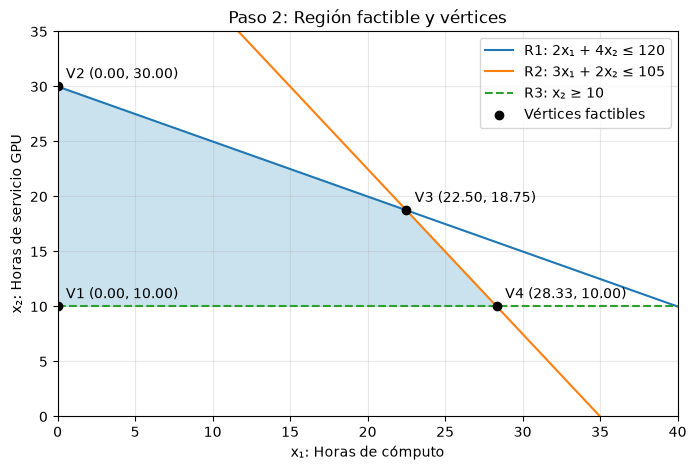

In [4]:
#Paso 2: Visualizar región factible y sus vértices
malla_x1 = np.linspace(0, 40, 400)
malla_x2 = np.linspace(0, 35, 400)
X1, X2 = np.meshgrid(malla_x1, malla_x2)

# Condiciones para identificar la zona factible
region_factible = (
    (2 * X1 + 4 * X2 <= 120) &
    (3 * X1 + 2 * X2 <= 105) &
    (X2 >= 10) &
    (X1 >= 0)
)

# Vértices que delimitan la región
vertices = np.array([
    [0.0, 10.0],
    [0.0, 30.0],
    [22.5, 18.75],
    [85/3, 10.0]
])

# Graficar
fig, ax = plt.subplots()
ax.contourf(X1, X2, region_factible.astype(int), levels=[0.5, 1.5], alpha=0.25, colors=["#2b8cbe"])
ax.plot(valores_x1, frontera_r1, label="R1: 2x₁ + 4x₂ ≤ 120")
ax.plot(valores_x1, frontera_r2, label="R2: 3x₁ + 2x₂ ≤ 105")
ax.plot(valores_x1, frontera_r3, linestyle="--", label="R3: x₂ ≥ 10")

ax.scatter(vertices[:, 0], vertices[:, 1], color="black", zorder=5, label="Vértices factibles")
for i, (vx, vy) in enumerate(vertices, start=1):
    ax.annotate(f"V{i} ({vx:.2f}, {vy:.2f})", (vx, vy), textcoords="offset points", xytext=(6, 6))

ax.set_xlim(0, 40)
ax.set_ylim(0, 35)
ax.set_xlabel("x₁: Horas de cómputo")
ax.set_ylabel("x₂: Horas de servicio GPU")
ax.set_title("Paso 2: Región factible y vértices")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()



Resultados de la optimización:
: True
x₁ (Cómputo): 22.5000 horas
x₂ (Servicio GPU): 18.7500 horas
Utilidad máxima Z: $2212.50


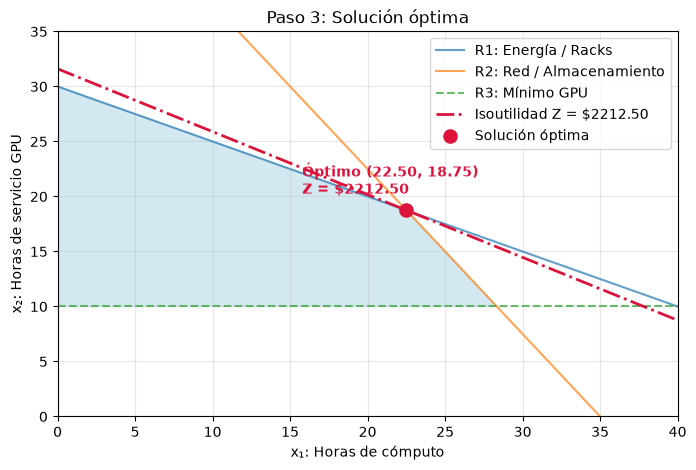

In [5]:
#Paso 3: Calcular y graficar solución óptima 
resultado = linprog(c=-coef_utilidad, A_ub=matriz_restricciones, b_ub=vector_limites, bounds=limites_variables, method="highs")

x1_opt, x2_opt = resultado.x
utilidad_max = -resultado.fun

print("Resultados de la optimización:")
print(f": {resultado.success}")
print(f"x₁ (Cómputo): {x1_opt:.4f} horas")
print(f"x₂ (Servicio GPU): {x2_opt:.4f} horas")
print(f"Utilidad máxima Z: ${utilidad_max:.2f}")

# Recta de isoutilidad
isoutilidad = (utilidad_max - 40 * valores_x1) / 70

fig, ax = plt.subplots()
ax.contourf(X1, X2, region_factible.astype(int), levels=[0.5, 1.5], alpha=0.2, colors=["#2b8cbe"])
ax.plot(valores_x1, frontera_r1, alpha=0.7, label="R1: Energía / Racks")
ax.plot(valores_x1, frontera_r2, alpha=0.7, label="R2: Red / Almacenamiento")
ax.plot(valores_x1, frontera_r3, linestyle="--", alpha=0.7, label="R3: Mínimo GPU")
ax.plot(valores_x1, isoutilidad, color="crimson", linewidth=2, linestyle="-.", label=f"Isoutilidad Z = ${utilidad_max:.2f}")

ax.scatter([x1_opt], [x2_opt], color="crimson", s=90, zorder=6, label="Solución óptima")
ax.annotate(
    f"Óptimo ({x1_opt:.2f}, {x2_opt:.2f})\nZ = ${utilidad_max:.2f}",
    (x1_opt, x2_opt),
    textcoords="offset points",
    xytext=(-75, 12),
    color="crimson",
    fontweight="bold"
)

ax.set_xlim(0, 40)
ax.set_ylim(0, 35)
ax.set_xlabel("x₁: Horas de cómputo")
ax.set_ylabel("x₂: Horas de servicio GPU")
ax.set_title("Paso 3: Solución óptima")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

In [6]:
#Evaluación de vértices y holguras
print("\nEvaluación de la utilidad en cada vértice:")
for indice, (vx, vy) in enumerate(vertices, start=1):
    valor_z = 40 * vx + 70 * vy
    print(f"Vértice V{indice} = ({vx:.2f}, {vy:.2f}) → Z = ${valor_z:.2f}")

consumo_energia = 2 * x1_opt + 4 * x2_opt
consumo_red = 3 * x1_opt + 2 * x2_opt

print("\nConsumo de recursos y holguras:")
print(f"Energía / Racks: {consumo_energia:.2f} / 120.00 | Holgura: {120 - consumo_energia:.2f}")
print(f"Red / Almacenamiento: {consumo_red:.2f} / 105.00 | Holgura: {105 - consumo_red:.2f}")
print(f"Horas GPU: {x2_opt:.2f} (Mínimo requerido: 10.00)")


Evaluación de la utilidad en cada vértice:
Vértice V1 = (0.00, 10.00) → Z = $700.00
Vértice V2 = (0.00, 30.00) → Z = $2100.00
Vértice V3 = (22.50, 18.75) → Z = $2212.50
Vértice V4 = (28.33, 10.00) → Z = $1833.33

Consumo de recursos y holguras:
Energía / Racks: 120.00 / 120.00 | Holgura: 0.00
Red / Almacenamiento: 105.00 / 105.00 | Holgura: 0.00
Horas GPU: 18.75 (Mínimo requerido: 10.00)
